# 04. Test evaluation and error analysis

This notebook reproduces `docs/06_evaluation_and_error_analysis.md`. The model was trained by `python -m hatari.models.train` after the selection was committed, and evaluated once on the test set by `python -m hatari.models.evaluate`. Running this notebook applies the same saved model to the same test messages again. No choice is made from it.

In [1]:
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def run_tests(*files):
    result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", *files], cwd=ROOT, capture_output=True, text=True)
    print(result.stdout.strip().splitlines()[-1])

## 1. Unit tests

In [2]:
run_tests("tests/test_train.py", "tests/test_uncertainty.py")

6 passed in 17.46s


## 2. Model and its training data

In [3]:
import json

import joblib

from hatari.models.evaluate import evaluate, load_test
from hatari.models.train import METADATA_FILE, MODEL_FILE, MODELS_DIR

metadata = json.loads((MODELS_DIR / METADATA_FILE).read_text())
display(pd.Series(metadata).to_frame("value"))
model = joblib.load(MODELS_DIR / MODEL_FILE)

,value
configuration,SVM_mask_C1
calibration,Platt scaling on out-of-fold margins of five grouped folds
threshold,0.5
training_messages,4929
training_by_language,"{'en': 4812, 'fr': 117}"
corpus_sha256,06cc991149c52dd5592385a49086ed4f6821d3c7a35cb59aab157d63b8adf3f4
model_sha256,82ff0534e951363c5662d7763cf0eeb4acb126509c339bbbeab57de6c6fa80f9
scikit_learn,1.5.2
trained_at,2026-11-22T17:02:45+00:00


## 3. Scores and intervals

In [4]:
test = load_test()
results, errors = evaluate(model, test)
display(results.round(4))
saved = pd.read_csv(ROOT / "reports" / "test_evaluation.csv")
print("identical to reports/test_evaluation.csv:", results.round(4).equals(saved))
display(pd.read_csv(ROOT / "reports" / "test_intervals.csv").round(3))

,language,messages,precision,recall,f1,accuracy,average_precision,true_negatives,false_positives,false_negatives,true_positives
0,en,1196,0.9950,0.9569,0.9756,0.9916,0.9953,986,1,9,200
1,fr,44,0.9333,1.0000,0.9655,0.9773,1.0000,29,1,0,14


identical to reports/test_evaluation.csv: True


,language,candidate,messages,groups,precision_low,precision_high,recall_low,recall_high,f1_low,f1_high
0,en,SVM_mask_C1,1196,1175,0.984,1.0,0.928,0.981,0.959,0.989
1,fr,SVM_mask_C1,44,18,0.786,1.0,1.000,1.000,0.880,1.000


**Findings**

- On 1,196 real English messages, precision 0.995, recall 0.957 and F1 0.976, with an F1 interval of 0.959 to 0.989.
- The French result rests on 44 synthetic texts in 18 groups. Its interval, 0.880 to 1, is wide, and cross-validation showed many false alarms on French legitimate texts.

## 4. Calibration

Brier score, English: 0.0077


,messages,mean_score,observed
score,,,
"(-0.001, 0.1]",982,0.007,0.006
"(0.1, 0.3]",10,0.159,0.300
"(0.3, 0.5]",3,0.372,0.000
"(0.5, 0.7]",1,0.583,0.000
"(0.7, 0.9]",13,0.819,1.000
"(0.9, 1.0]",187,0.982,1.000


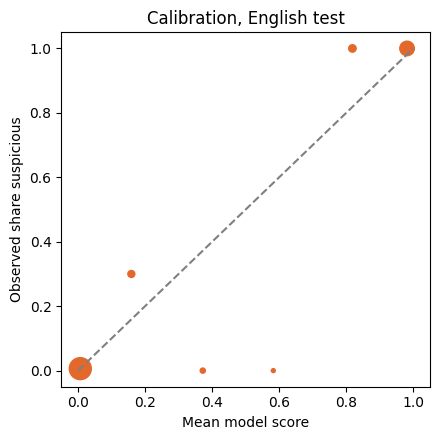

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import brier_score_loss

scored = test.assign(score=model.predict_proba(test["text"])[:, 1])
english = scored[scored["language"] == "en"]
print("Brier score, English:", round(brier_score_loss(english["suspicious"], english["score"]), 4))
bins = pd.cut(english["score"], [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0], include_lowest=True)
table = english.groupby(bins, observed=True).agg(messages=("score", "size"), mean_score=("score", "mean"),
                                                  observed=("suspicious", "mean"))
display(table.round(3))
figure, axis = plt.subplots(figsize=(4.5, 4.5))
axis.plot([0, 1], [0, 1], linestyle="--", color="grey")
axis.scatter(table["mean_score"], table["observed"], s=np.sqrt(table["messages"]) * 8, color="#E2692B")
axis.set_xlabel("Mean model score")
axis.set_ylabel("Observed share suspicious")
axis.set_title("Calibration, English test")
plt.tight_layout()
plt.show()

**Finding.** The score agrees with the observed share where most messages fall. It reflects the prevalence of these collections, about 17% suspicious, so it is not shown to users as a probability of fraud.

## 5. Every error

In [6]:
display(errors[["language", "error", "score", "sources", "text"]])

,language,error,score,sources,text
515,en,false_negative,0.011189,mendeley_smishing+uci_sms_spam,How come it takes so little time for a child who is afraid of the dark to become a teenager who wants to stay out al...
1046,en,false_negative,0.024749,mendeley_smishing,"Swayamvara By David Hair,�Swayamvara� (The Return of Ravana Book 2) by David Hair is a story of reincarnation, two s..."
573,en,false_negative,0.064627,mendeley_smishing+uci_sms_spam,"LookAtMe!: Thanks for your purchase of a video clip from LookAtMe!, you've been charged 35p. Think you can do better..."
1027,en,false_negative,0.087914,mendeley_smishing,Overcome programming challenges for multicore and learn the techniques to scale reliability. Attend Intel session at...
166,en,false_negative,0.090309,mendeley_smishing+uci_sms_spam,Filthy stories and GIRLS waiting for your
1030,en,false_negative,0.097081,mendeley_smishing,My name is Theresa & I have 7.3milion Dollar to transfer to you for charity work to help the poor ones in ur place i...
514,en,false_negative,0.110375,mendeley_smishing+uci_sms_spam,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-C...
736,en,false_negative,0.158264,mendeley_smishing+uci_sms_spam,You will be receiving this week's Triple Echo ringtone shortly. Enjoy it!
617,en,false_negative,0.209276,mendeley_smishing+uci_sms_spam,Sorry I missed your call let's talk when you have the time. I'm on 07090201529
807,en,false_positive,0.582516,mendeley_smishing+uci_sms_spam,Mathews or tait or edwards or anderson


**Findings**

- Five of the nine missed messages are promotions or jokes, with little risk.
- An advance-fee message and a callback scam are missed. Rules on money promises, contact requests and premium numbers are needed in addition to the model.
- The two false alarms are a short list of names and a formal French email.